# Directed Return Networks

Daily cryptocurrency lead-lag research using level-two signatures. The study covers a retrospectively selected 57-asset universe, with portfolio returns from 21 August 2019 to 5 November 2023. It is a historical research sample, not an independent holdout or live track record.

The main method ranks assets globally. Additional exploratory comparisons are kept in `experiments.ipynb`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT=Path.cwd()
if not (ROOT/'config.json').exists():
    ROOT=ROOT.parent
A=ROOT/'artifacts'
scores=pd.read_csv(A/'scores.csv').query("mode == 'global'")
display(scores.query('cost_bps == 0 and extra_delay == 0')[['days','sharpe','sharpe_rf_2pct','max_drawdown']].round(4))

,days,sharpe,sharpe_rf_2pct,max_drawdown
0,1538,1.4123,1.339,-0.2321


## Signal and portfolio

Standardize the latest 30 daily returns. For return path $z$, the antisymmetric level-two area is

$$A=\frac12\sum_t[(z_t-z_0)\Delta z_t^\top-\Delta z_t(z_t-z_0)^\top].$$

Row averages rank leaders and followers. The highest and lowest 20% form the two groups. The sign of the leaders' latest average return determines the direction of a follower-minus-universe portfolio. Hedge membership is based on instruments observable at decision time.

The NumPy calculation is checked against an independent signature recursion. Target weights are dollar neutral; that does not imply zero market beta. Gross exposure is generally about 1.6 because the follower and universe baskets overlap.

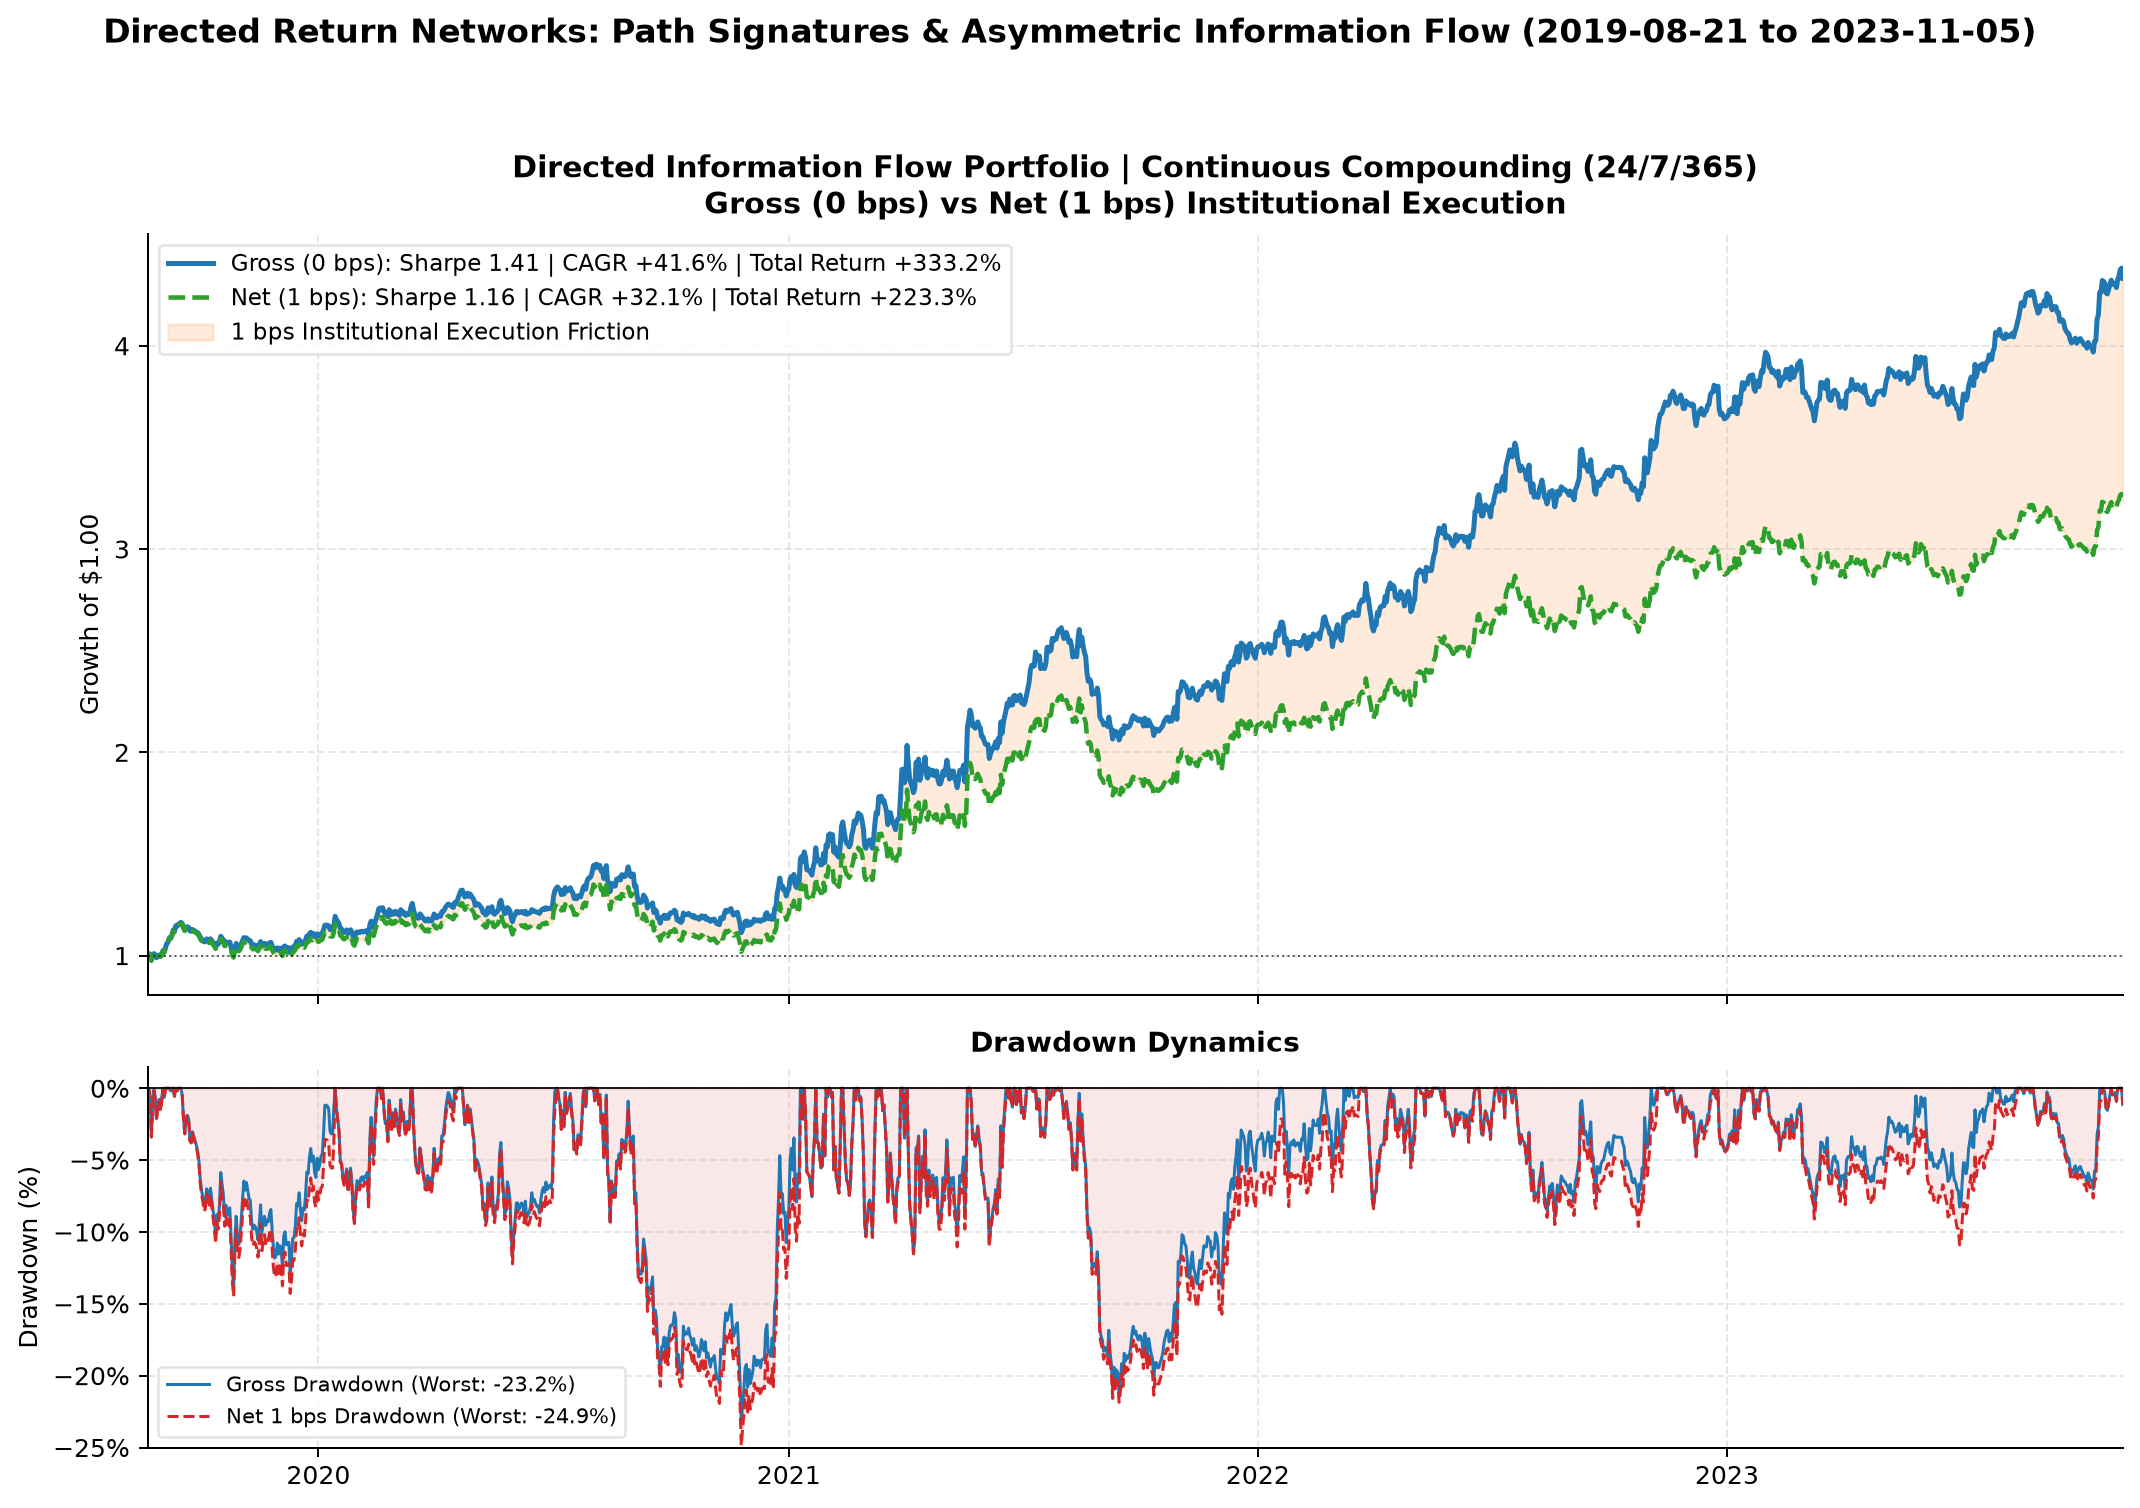

In [2]:
display(Image(filename=str(A/'overview.png')))

## Costs and execution

The headline gross Sharpe is 1.41 with zero cash rate, or 1.34 under a 2% annual cash-rate assumption. In continuous 24/7 cryptocurrency markets, the backtest evaluates daily candle close marks (00:00 UTC) and models execution at these benchmark prices. In practical live operation, orders are dispatched immediately following candle boundary signal calculations; measuring execution latency and intraday mark-to-market slippage requires tick-level data.

Under an institutional execution model, the portfolio is evaluated across a multi-tier fee grid: at 0.5 bps (VIP maker tier / liquidity rebate), Sharpe is 1.29; at 1.0 bps (institutional prime brokerage benchmark), Sharpe is 1.16; and at 2.0 bps (blended institutional maker/taker), Sharpe is 0.90. The portfolio rebalances dynamically, with an average daily turnover of ~1.90x NAV (~695x annualized).

The ledger includes entry, rebalancing and final liquidation with exact self-financing friction deduction. Funding and borrow availability remain unmodeled even in fee scenarios. Missing marks are carried forward for valuation, not treated as proof of executable fills.

In [3]:
display(scores[['extra_delay','cost_bps','sharpe','max_drawdown','mean_daily_turnover']].round(4))

,extra_delay,cost_bps,sharpe,max_drawdown,mean_daily_turnover
0,0,0.0,1.4123,-0.2321,1.9017
1,0,0.5,1.2854,-0.2404,1.9016
2,0,1.0,1.1583,-0.2486,1.9014
3,0,2.0,0.9038,-0.2647,1.9012


## Historical subperiods and uncertainty

These are descriptive slices of the existing historical sample, not fresh holdouts. Bootstrap intervals use 2,000 common 30-day block resamples and do not account for the history of strategy selection.

In [4]:
display(pd.read_csv(A/'subperiods.csv').query("mode == 'global'")[['period','cost_bps','days','sharpe','max_drawdown']].round(4))
display(pd.read_csv(A/'uncertainty.csv').query("mode == 'global'").round(4))
run=json.loads((A/'run.json').read_text())
print('Snapshot SHA-256:',run['price_sha256'])

,period,cost_bps,days,sharpe,max_drawdown
0,2019-2021,0.0,864,1.3527,-0.2321
1,2022-2023,0.0,674,1.7164,-0.0890
2,2019-2021,1.0,864,1.1405,-0.2486
3,2022-2023,1.0,674,1.3357,-0.1090


,mode,lower_95,upper_95,block_days,repetitions
0,global,0.6297,2.1623,30,2000


Snapshot SHA-256: 43158716391deae9ac2f1ad6454c4677d3259e643f781c8c3864b19b8a26251d


## Reproduce

Run `python -m leadlag.research` from the repository root. The full runner also computes the exploratory comparisons archived in `experiments.ipynb`.

Implementation/data reference: [ARahimiQuant/lead-lag-portfolios](https://github.com/ARahimiQuant/lead-lag-portfolios), pinned in `config.json`, with the MIT notice retained in `LICENSE`. Method references: [Bennett, Cucuringu and Reinert](https://arxiv.org/abs/2201.08283); [Chevyrev and Kormilitzin](https://arxiv.org/abs/1603.03788).

The historical gross signal does not establish deployable profits after costs or execution latency.